# TP2 - Apprentissage non supervisé avec Python

**Étudiant :** Maxim Khomenko

**Numéro du TP :** 2

**Date :** 17 Novembre 2026

**Version Python :** 3.13.5

**Bibliothèques utilisées :** sys, numpy, pandas, warnings, scikit-learn, matplotlib

In [1]:
import sys
import numpy as np
np.set_printoptions(threshold=sys.maxsize) # np.nan n'est plus accepté
import pandas as pd
import warnings
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn import metrics

Inertie cumulée (%) : [ 87.3  99.   99.5  99.7  99.8  99.9  99.9 100.  100.  100.  100.  100. ]
    janv   fev  mars  avril   mai  juin  juil  aout  sept   oct   nov   dec
F1  0.27  0.29  0.30   0.30  0.28  0.28  0.27  0.29  0.30  0.30  0.29  0.27
F2  0.40  0.30  0.13  -0.12 -0.32 -0.36 -0.39 -0.30 -0.11  0.12  0.26  0.39


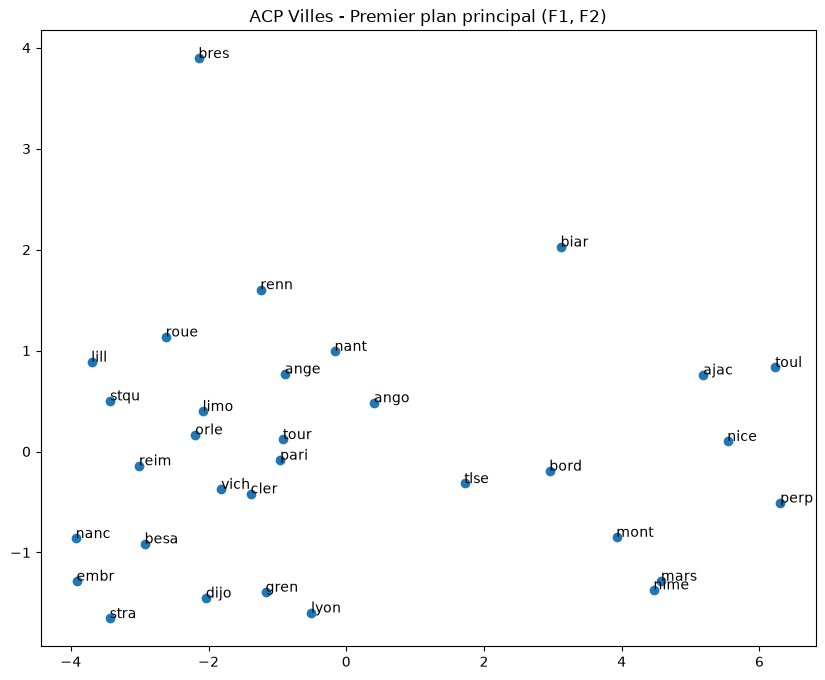

In [2]:
# 1. Importer le jeu de données
data_villes = pd.read_csv('villes.csv', sep=';') # type: ignore
X_villes = data_villes.iloc[:, 1:13].values # utilisation de .iloc car .ix est déprécié
labels_villes = data_villes.iloc[:, 0].values

# 2. ACP sur jeu de données centrées réduites
X_villes_std = StandardScaler().fit_transform(X_villes)
acp_villes = PCA()
acp_villes.fit(X_villes_std)

# Inertie cumulée
print("Inertie cumulée (%) :", np.round(acp_villes.explained_variance_ratio_.cumsum() * 100, 1))

# Coefficients des deux premières composantes principales
coefficients = acp_villes.components_[:2]
df_coefficients_villes = pd.DataFrame(coefficients, index=["F1", "F2"], columns=data_villes.columns[1:13])
print(df_coefficients_villes.round(2))

# Visualisation des villes dans le premier plan principal
X_acp_villes = acp_villes.transform(X_villes_std)
plt.figure(figsize=(10, 8))
plt.scatter(X_acp_villes[:, 0], X_acp_villes[:, 1])
for label, x, y in zip(labels_villes, X_acp_villes[:, 0], X_acp_villes[:, 1]):
  plt.annotate(label, xy=(x, y), xytext=(-0.2, 0.2), textcoords='offset points')
plt.title("ACP Villes - Premier plan principal (F1, F2)")
plt.show()

**Nombre d'axes à retenir :** Le premier axe résume déjà 87,3 % de l'information, donc il suffit largement pour dépasser le seuil de 70 %. Si on garde les deux premiers axes, on monte à 99 %, ce qui est parfait pour faire une représentation graphique.

**Interprétation des axes :**
* **Axe 1 (F1)** : tous les mois ont des coefficients positifs et à peu près égaux. Ça veut dire que cet axe capte la température moyenne sur l'année. Il oppose tout simplement les villes chaudes aux villes froides. C'est d'ailleurs ce qu'on peut voir sur le graphique. À l'extrême droite de l'axe F1, on trouve des villes du Sud très chaudes comme Toulon, Perpignan, Ajaccio ou Nice, et à l'extrême gauche, on trouve des villes globalement plus froides comme Strasbourg, Nancy ou Embrun.
* **Axe 2 (F2)** : si on regarde les chiffres en détail, cet axe oppose toute la période froide de l'année (d'octobre à mars, avec des coefficients positifs) à la période chaude (d'avril à septembre, avec des coefficients négatifs). Il représente donc la différence de température entre les saisons.

Inertie cumulée (%) : [ 58.8  76.5  86.8  91.4  95.1  98.2 100. ]
    Meutre  Rapt   Vol  Attaque  Viol  Larcin  Auto_Theft
F1    0.30  0.43  0.40     0.40  0.44    0.36         0.3
F2    0.63  0.17 -0.04     0.34 -0.20   -0.40        -0.5


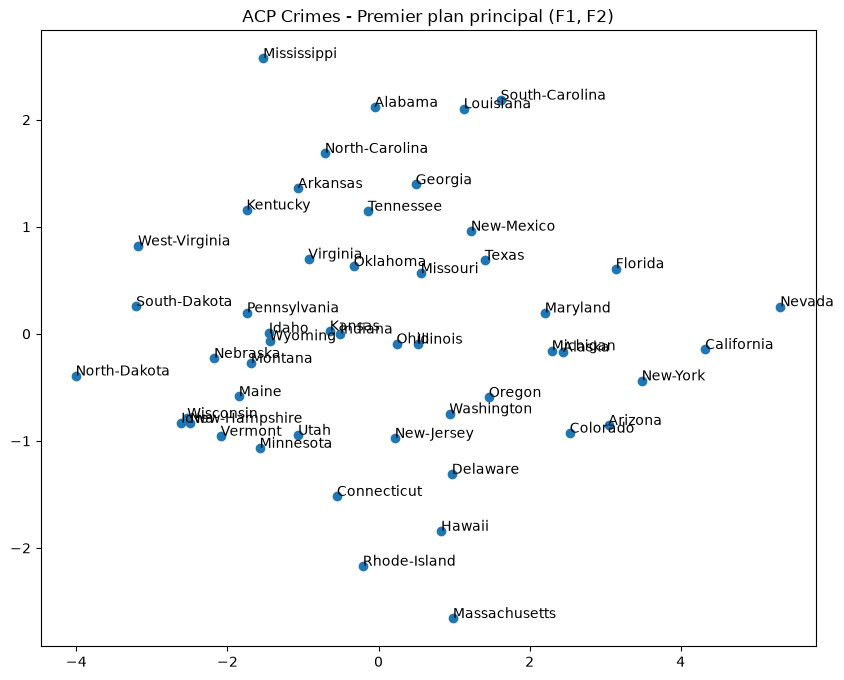

In [3]:
data_crimes = pd.read_csv('crimes.csv', sep=';') # type: ignore
X_crimes = data_crimes.iloc[:, 1:8].values
labels_crimes = data_crimes.iloc[:, 0].values

X_crimes_std = StandardScaler().fit_transform(X_crimes)
acp_crimes = PCA()
acp_crimes.fit(X_crimes_std)

print("Inertie cumulée (%) :", np.round(acp_crimes.explained_variance_ratio_.cumsum() * 100, 1))

coefficients_crimes = acp_crimes.components_[:2]
df_coefficients_crimes = pd.DataFrame(coefficients_crimes, index=["F1", "F2"], columns=data_crimes.columns[1:8])
print(df_coefficients_crimes.round(2))

X_acp_crimes = acp_crimes.transform(X_crimes_std)
plt.figure(figsize=(10, 8))
plt.scatter(X_acp_crimes[:, 0], X_acp_crimes[:, 1])
for label, x, y in zip(labels_crimes, X_acp_crimes[:, 0], X_acp_crimes[:, 1]):
  plt.annotate(label, xy=(x, y), xytext=(-0.2, 0.2), textcoords='offset points')
plt.title("ACP Crimes - Premier plan principal (F1, F2)")
plt.show()

**Nombre d'axes à retenir :** Le premier axe ne résume que 58,8 % de l'information, ce qui ne suffit pas pour atteindre les 70 % demandés. En combinant les deux premiers axes, on monte à 76,5 %, il faut donc bien en garder deux.

**Interprétation des axes :**
* **Axe 1 (F1)** : tous les types de crimes ont des coefficients positifs. Ça veut dire que cet axe mesure le niveau global de criminalité. Il oppose les États où il y a beaucoup de crimes en général à ceux où il y en a très peu. C'est ce qu'on peut voir sur le graphique aussi, à l'extrême droite de l'axe F1 (criminalité très forte), on trouve des États comme le Nevada, la Californie ou New York. À l'extrême gauche de l'axe (criminalité très faible), on a des États calmes et ruraux comme le Dakota du Nord, le Dakota du Sud ou la Virginie-Occidentale.
* **Axe 2 (F2)** : il oppose surtout les meurtres et les agressions (très positifs) aux vols de voitures et aux larcins (très négatifs). Mais on ne peut pas dire que c'est juste crimes violents contre délits matériels car le viol a aussi un coefficient négatif. Cet axe montre plutôt deux profils d'États, ceux marqués par les homicides et les agressions d'un côté, et ceux marqués par les vols et les viols de l'autre. C'est un peu douteux de voir le viol regroupé avec les vols de voitures plutôt qu'avec les autres crimes violents, mais c'est ce que donnent les chiffres de ce jeu de données.

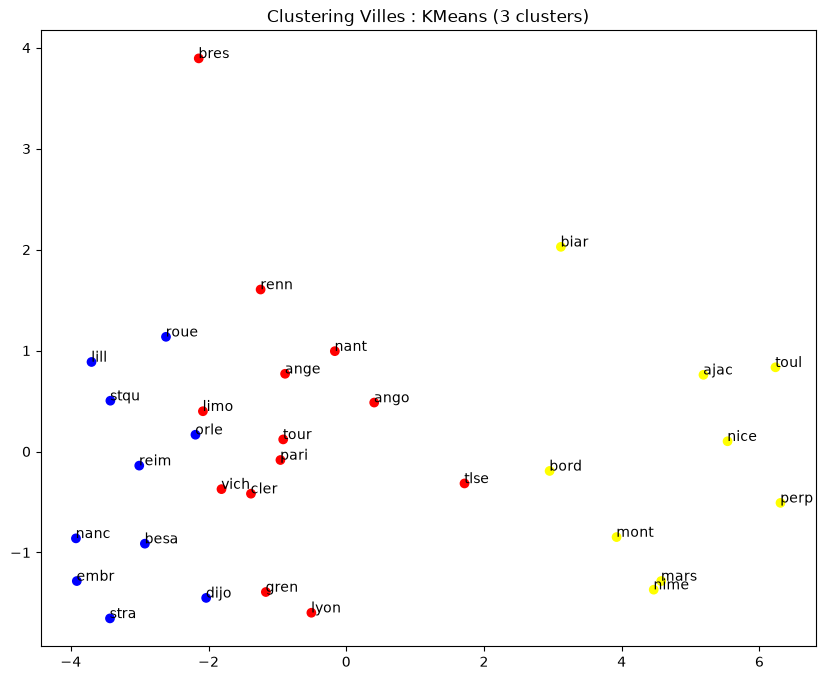

In [4]:
# 1. KMeans avec 3 clusters sur les données Villes
clustering_kmeans = KMeans(n_clusters=3, random_state=0).fit_predict(X_villes_std)

colors = ['red', 'yellow', 'blue']
plt.figure(figsize=(10, 8))
plt.scatter(X_acp_villes[:, 0], X_acp_villes[:, 1], c=clustering_kmeans, cmap=matplotlib.colors.ListedColormap(colors))
for label, x, y in zip(labels_villes, X_acp_villes[:, 0], X_acp_villes[:, 1]):
  plt.annotate(label, xy=(x, y), xytext=(-0.2, 0.2), textcoords='offset points')
plt.title("Clustering Villes : KMeans (3 clusters)")
plt.show()

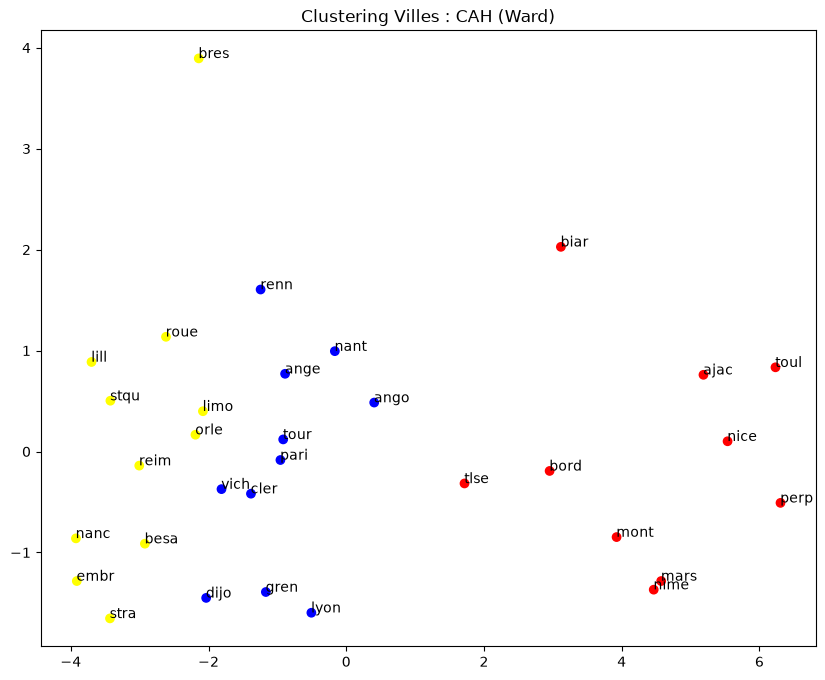

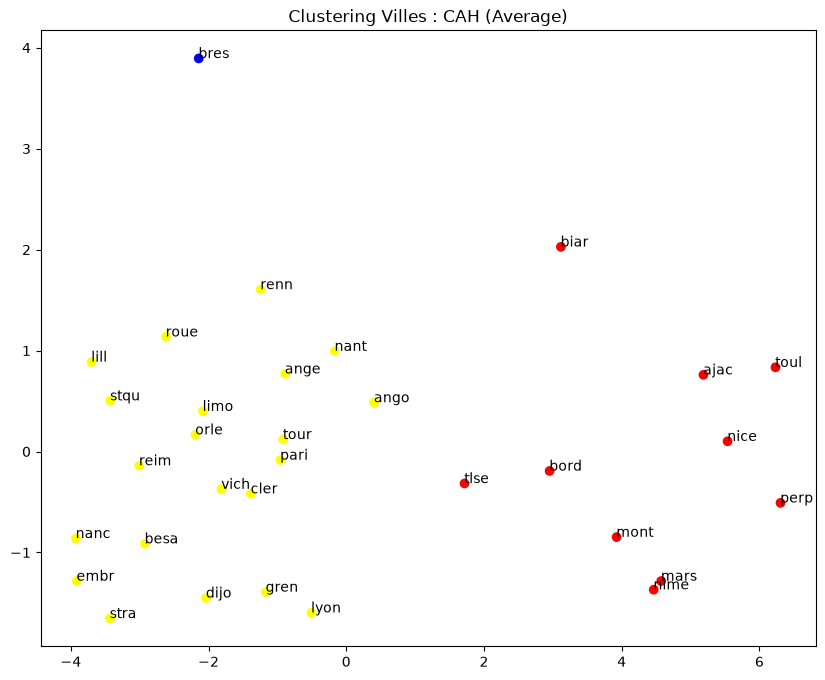

In [5]:
# 2. AgglomerativeClustering (Ward)
clustering_ward = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_villes_std)

plt.figure(figsize=(10, 8))
plt.scatter(X_acp_villes[:, 0], X_acp_villes[:, 1], c=clustering_ward, cmap=matplotlib.colors.ListedColormap(colors))
for label, x, y in zip(labels_villes, X_acp_villes[:, 0], X_acp_villes[:, 1]):
  plt.annotate(label, xy=(x, y), xytext=(-0.2, 0.2), textcoords='offset points')
plt.title("Clustering Villes : CAH (Ward)")
plt.show()

# AgglomerativeClustering (Average)
clustering_avg = AgglomerativeClustering(n_clusters=3, linkage='average').fit_predict(X_villes_std)

plt.figure(figsize=(10, 8))
plt.scatter(X_acp_villes[:, 0], X_acp_villes[:, 1], c=clustering_avg, cmap=matplotlib.colors.ListedColormap(colors))
for label, x, y in zip(labels_villes, X_acp_villes[:, 0], X_acp_villes[:, 1]):
  plt.annotate(label, xy=(x, y), xytext=(-0.2, 0.2), textcoords='offset points')
plt.title("Clustering Villes : CAH (Average)")
plt.show()

In [6]:
# 3. Recherche de la meilleure partition KMeans avec l'indice Silhouette
for i in np.arange(2, 6):
  clustering_i = KMeans(n_clusters=i, random_state=0).fit_predict(X_villes_std)
  score = metrics.silhouette_score(X_villes_std, clustering_i, metric='euclidean')
  print(f"Indice Silhouette pour k={i} : {round(score, 3)}")

Indice Silhouette pour k=2 : 0.626
Indice Silhouette pour k=3 : 0.374
Indice Silhouette pour k=4 : 0.344
Indice Silhouette pour k=5 : 0.344


**Déduction de la meilleure partition :**

En testant les partitions de 2 à 5 groupes avec notre boucle, on voit clairement que l'indice de Silhouette atteint son maximum pour K=2, avec un score de 0,626 (les autres stagnent autour de 0,34 - 0,37). Comme le cours l'indique, on choisit le K qui donne le score le plus élevé car c'est là que les groupes sont les mieux séparés. La meilleure partition pour classer nos villes est donc celle à deux clusters.